# Phần 2 — Kết hợp các nguồn

Phần 1 nhìn từng nguồn riêng lẻ. Phần này **ghép các nguồn** để trả lời những câu hỏi mà không nguồn nào trả lời được một mình: chất lượng (IMDb) so với thành công thương mại (TMDb), cơ cấu sản xuất so với cơ cấu doanh thu, chất lượng kho phim của từng nền tảng streaming.

Khóa nối chung là **mã phim IMDb (`tconst`)**: TMDb trả về `imdb_id` cho mỗi phim; MagnetDB không có khóa này nên phải **ghép thực thể** từ tên file/torrent (chương 3). Biểu đồ lưu vào `plots/5_combined/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "5_combined"
SRC = "Nguồn: IMDb, TMDb API (2026; dữ liệu streaming do JustWatch cung cấp)."
SRC_FIN = "Nguồn: IMDb, TMDb API (2026)."
P = lambda name: (V.DC / name).as_posix()

mv = duckdb.sql(f"""
    SELECT t.*, i.genres, i.start_year, i.num_votes, i.avg_rating, i.runtime_min
    FROM read_parquet('{P("tmdb_movies.parquet")}') t
    JOIN read_parquet('{P("imdb_movies_all.parquet")}') i ON i.tconst = t.imdb_id
    WHERE t.tmdb_found AND NOT i.is_adult
""").df()
fin = mv[(mv["budget"] >= 1e6) & (mv["revenue"] >= 1e4) & mv["release_date"].dt.year.between(1980, 2024)
         & (mv["num_votes"] >= 1000)].copy()
money = FuncFormatter(lambda x, _: "$0" if x == 0 else (f"${x / 1e9:.0f} tỷ" if x >= 1e9 else
                      (f"${x / 1e6:.0f} tr" if x >= 1e6 else f"${x / 1e3:.0f}k")))
print(f"{len(mv):,} phim có cả IMDb và TMDb; {len(fin):,} có số liệu tài chính và ≥ 1.000 vote")

135,585 phim có cả IMDb và TMDb; 8,920 có số liệu tài chính và ≥ 1.000 vote


## 1. Ba nguồn nối với nhau như thế nào?

  wrote plots\5_combined\01_integration_diagram.png


WindowsPath('D:/dulieulon/plots/5_combined/01_integration_diagram.png')

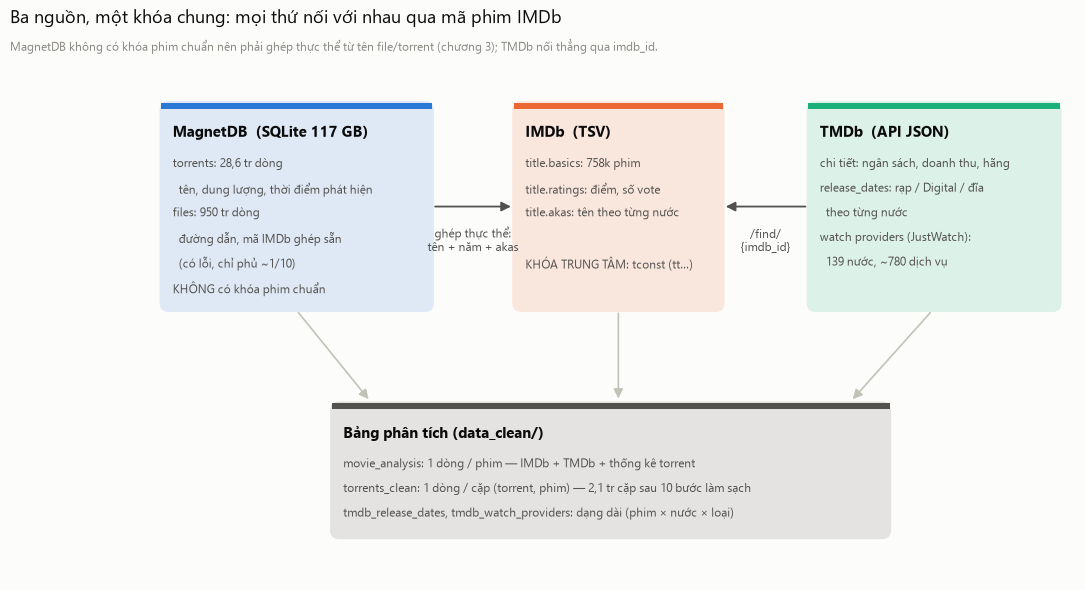

In [3]:
fig, ax = plt.subplots(figsize=(12, 6.6))
ax.set_xlim(0, 12)
ax.set_ylim(0, 6.6)
ax.axis("off")


def box(x, y, w, h, title, lines, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=color, edgecolor="none", alpha=0.14))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.08), w, 0.08, boxstyle="square,pad=0", facecolor=color, edgecolor="none"))
    ax.text(x + 0.15, y + h - 0.3, title, fontsize=11, color=V.INK, va="top", weight="bold")
    for i, l in enumerate(lines):
        ax.text(x + 0.15, y + h - 0.72 - i * 0.32, l, fontsize=8.8, color=V.INK2, va="top")


def arrow(a, b, label, dy=0.12):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, color=V.INK2, linewidth=1.3))
    ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + dy, label, fontsize=8.5, color=V.INK2, ha="center", va="bottom")


box(0.2, 3.5, 3.5, 2.7, "MagnetDB  (SQLite 117 GB)",
    ["torrents: 28,6 tr dòng", "  tên, dung lượng, thời điểm phát hiện", "files: 950 tr dòng",
     "  đường dẫn, mã IMDb ghép sẵn", "  (có lỗi, chỉ phủ ~1/10)", "KHÔNG có khóa phim chuẩn"], V.BLUE)
box(4.75, 3.5, 2.7, 2.7, "IMDb  (TSV)",
    ["title.basics: 758k phim", "title.ratings: điểm, số vote", "title.akas: tên theo từng nước",
     "", "KHÓA TRUNG TÂM: tconst (tt…)"], V.ORANGE)
box(8.55, 3.5, 3.25, 2.7, "TMDb  (API JSON)",
    ["chi tiết: ngân sách, doanh thu, hãng", "release_dates: rạp / Digital / đĩa", "  theo từng nước",
     "watch providers (JustWatch):", "  139 nước, ~780 dịch vụ"], V.AQUA)
arrow((3.7, 4.85), (4.75, 4.85), "ghép thực thể:\ntên + năm + akas", dy=-0.62)
arrow((8.55, 4.85), (7.45, 4.85), "/find/\n{imdb_id}", dy=-0.62)
box(2.4, 0.55, 7.2, 1.75, "Bảng phân tích (data_clean/)",
    ["movie_analysis: 1 dòng / phim — IMDb + TMDb + thống kê torrent",
     "torrents_clean: 1 dòng / cặp (torrent, phim) — 2,1 tr cặp sau 10 bước làm sạch",
     "tmdb_release_dates, tmdb_watch_providers: dạng dài (phim × nước × loại)"], V.INK2)
for x0 in (1.95, 6.1, 10.15):
    ax.add_patch(FancyArrowPatch((x0, 3.5), (min(max(x0, 2.9), 9.1), 2.32), arrowstyle="-|>", mutation_scale=14,
                                 color=V.AXIS, linewidth=1.2, connectionstyle="arc3,rad=0"))
fig.text(0.012, 0.975, "Ba nguồn, một khóa chung: mọi thứ nối với nhau qua mã phim IMDb", color=V.INK, fontsize=13, va="top")
fig.text(0.012, 0.93, "MagnetDB không có khóa phim chuẩn nên phải ghép thực thể từ tên file/torrent (chương 3); "
         "TMDb nối thẳng qua imdb_id.", color=V.MUTED, fontsize=8.5, va="top")
V.save(fig, FOLDER, "01_integration_diagram")

**Nhận xét.** IMDb là **trục trung tâm**: TMDb nối thẳng qua `imdb_id` (gọi API `/find`), còn MagnetDB chỉ có tên file tự do nên cần một bước **ghép thực thể** (tên + năm + tên theo từng nước trong `title.akas`). Kết quả là các bảng phân tích trong `data_clean/` — mỗi bảng ở một mức chi tiết khác nhau (phim, cặp torrent–phim, phim × nước × loại phát hành).

## 2. Phim hay có ăn khách không? (IMDb × TMDb)

  wrote plots\5_combined\02_rating_vs_revenue.png


WindowsPath('D:/dulieulon/plots/5_combined/02_rating_vs_revenue.png')

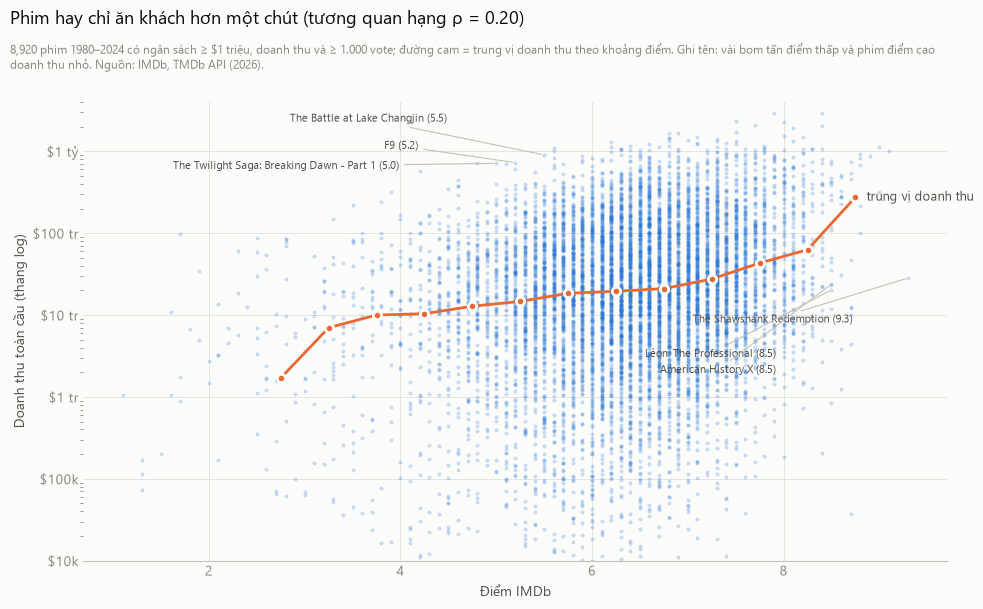

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.2))
V.style_axes(ax, grid="both")
ax.scatter(fin["avg_rating"], fin["revenue"], s=8, color=V.BLUE, alpha=0.25, linewidths=0)
bins = np.arange(2, 9.6, 0.5)
med = fin.groupby(pd.cut(fin["avg_rating"], bins), observed=False)["revenue"].median()
cnt = fin.groupby(pd.cut(fin["avg_rating"], bins), observed=False).size()
mid = [b.mid for b in med.index]
ok = cnt.values >= 20
ax.plot(np.array(mid)[ok], med.values[ok], color=V.ORANGE, marker="o", markersize=6, markeredgecolor=V.SURFACE,
        markeredgewidth=2)
ax.annotate("trung vị doanh thu", xy=(np.array(mid)[ok][-1], med.values[ok][-1]), xytext=(8, 0),
            textcoords="offset points", va="center", color=V.INK2, fontsize=9)
rho = fin[["avg_rating", "revenue"]].corr(method="spearman").iloc[0, 1]
# ghi tên so le (dy) và nối bằng đường mảnh để không chồng nhau
for (_, r), dy in zip(fin[(fin["avg_rating"] < 5.6)].nlargest(3, "revenue").iterrows(), (26, 12, -2)):
    ax.annotate(f"{r['tmdb_title']} ({r['avg_rating']:.1f})", xy=(r["avg_rating"], r["revenue"]), xytext=(-70, dy),
                textcoords="offset points", ha="right", va="center", color=V.INK2, fontsize=8,
                arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
for (_, r), dy in zip(fin[(fin["avg_rating"] >= 8.3) & (fin["revenue"] < 3e7)].nlargest(3, "num_votes").iterrows(),
                      (-30, -46, -62)):
    ax.annotate(f"{r['tmdb_title']} ({r['avg_rating']:.1f})", xy=(r["avg_rating"], r["revenue"]), xytext=(-40, dy),
                textcoords="offset points", ha="right", va="center", color=V.INK2, fontsize=8,
                arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
ax.set_yscale("log")
ax.set_ylim(1e4, 4e9)
ax.yaxis.set_major_formatter(money)
ax.set_xlabel("Điểm IMDb")
ax.set_ylabel("Doanh thu toàn cầu (thang log)")
V.titles(fig, f"Phim hay chỉ ăn khách hơn một chút (tương quan hạng ρ = {rho:.2f})",
         f"{len(fin):,} phim 1980–2024 có ngân sách ≥ $1 triệu, doanh thu và ≥ 1.000 vote; đường cam = trung vị doanh thu theo "
         f"khoảng điểm. Ghi tên: vài bom tấn điểm thấp và phim điểm cao doanh thu nhỏ. {SRC_FIN}")
V.save(fig, FOLDER, "02_rating_vs_revenue")

**Nhận xét.** Có, nhưng **yếu**: tương quan hạng Spearman chỉ **ρ ≈ 0,20**. Trung vị doanh thu tăng theo điểm, nhưng ở mọi mức điểm, doanh thu dao động hàng nghìn lần. Có những bom tấn tỷ đô bị chấm thấp (*Twilight: Breaking Dawn – Part 1* 5,0, *F9* 5,2) và những phim kinh điển điểm rất cao nhưng doanh thu phòng vé nhỏ (*The Shawshank Redemption* 9,3) — thành công thương mại phụ thuộc vào marketing, thương hiệu, lịch chiếu… nhiều hơn chất lượng.

## 3. Nhiều tiền hơn có làm phim hay hơn? (IMDb × TMDb)

  wrote plots\5_combined\03_budget_tier_raincloud.png


WindowsPath('D:/dulieulon/plots/5_combined/03_budget_tier_raincloud.png')

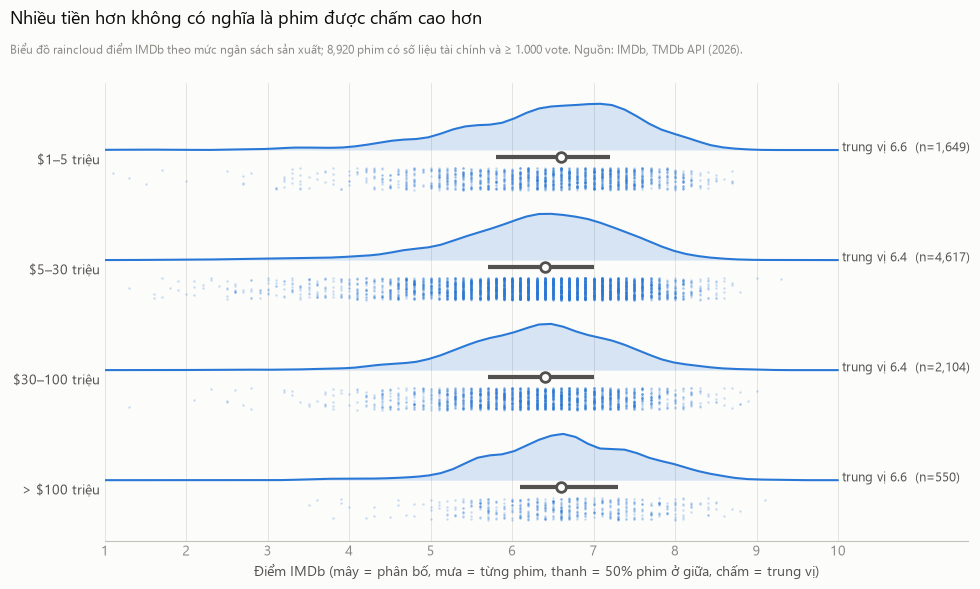

In [5]:
TIERS = [(1e6, 5e6, "$1–5 triệu"), (5e6, 30e6, "$5–30 triệu"), (30e6, 100e6, "$30–100 triệu"), (100e6, 1e10, "> $100 triệu")]
fig, ax = plt.subplots(figsize=(10, 6))
V.style_axes(ax, grid="x")
rng = np.random.default_rng(0)
for i, (lo, hi, lbl) in enumerate(TIERS):
    vals = fin.loc[fin["budget"].between(lo, hi, inclusive="left"), "avg_rating"].values
    y = len(TIERS) - 1 - i
    kde_x = np.linspace(1, 10, 300)
    hist, edges = np.histogram(vals, bins=60, range=(1, 10), density=True)
    dens = np.interp(kde_x, (edges[:-1] + edges[1:]) / 2, np.convolve(hist, np.hanning(7) / np.hanning(7).sum(), "same"))
    dens = dens / dens.max() * 0.42
    ax.fill_between(kde_x, y + 0.08, y + 0.08 + dens, color=V.BLUE, alpha=0.18, linewidth=0)
    ax.plot(kde_x, y + 0.08 + dens, color=V.BLUE, linewidth=1.5)
    jitter = rng.uniform(-0.28, -0.08, size=len(vals))
    ax.scatter(vals, y + jitter, s=3, color=V.BLUE, alpha=0.25, linewidths=0)
    q1, q2, q3 = np.percentile(vals, [25, 50, 75])
    ax.plot([q1, q3], [y + 0.02, y + 0.02], color=V.INK2, linewidth=3, solid_capstyle="butt")
    ax.plot(q2, y + 0.02, "o", markersize=7, color=V.SURFACE, markeredgecolor=V.INK2, markeredgewidth=2)
    ax.text(10.05, y + 0.1, f"trung vị {q2:.1f}  (n={len(vals):,})", va="center", color=V.INK2, fontsize=9)
ax.set_yticks(range(len(TIERS)))
ax.set_yticklabels([t[2] for t in TIERS][::-1], color=V.INK2)
ax.set_xlim(1, 11.6)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Điểm IMDb (mây = phân bố, mưa = từng phim, thanh = 50% phim ở giữa, chấm = trung vị)")
V.titles(fig, "Nhiều tiền hơn không có nghĩa là phim được chấm cao hơn",
         f"Biểu đồ raincloud điểm IMDb theo mức ngân sách sản xuất; {len(fin):,} phim có số liệu tài chính và ≥ 1.000 vote. {SRC_FIN}")
V.save(fig, FOLDER, "03_budget_tier_raincloud")

**Nhận xét.** **Không.** Trung vị điểm gần như bằng nhau ở mọi mức ngân sách (6,4–6,6); phim kinh phí thấp còn có đuôi điểm cao dài hơn. Ngân sách lớn giúp phim **ít khi quá tệ** (đuôi dưới ngắn hơn) nhưng không đảm bảo phim hay. Biểu đồ *raincloud* kết hợp phân bố (mây), từng phim (mưa) và tóm tắt (thanh + chấm) trong một hình.

## 4. Thể loại: nhiều phim có nghĩa là nhiều tiền? (IMDb × TMDb)

  wrote plots\5_combined\04_genre_count_vs_revenue_slope.png


WindowsPath('D:/dulieulon/plots/5_combined/04_genre_count_vs_revenue_slope.png')

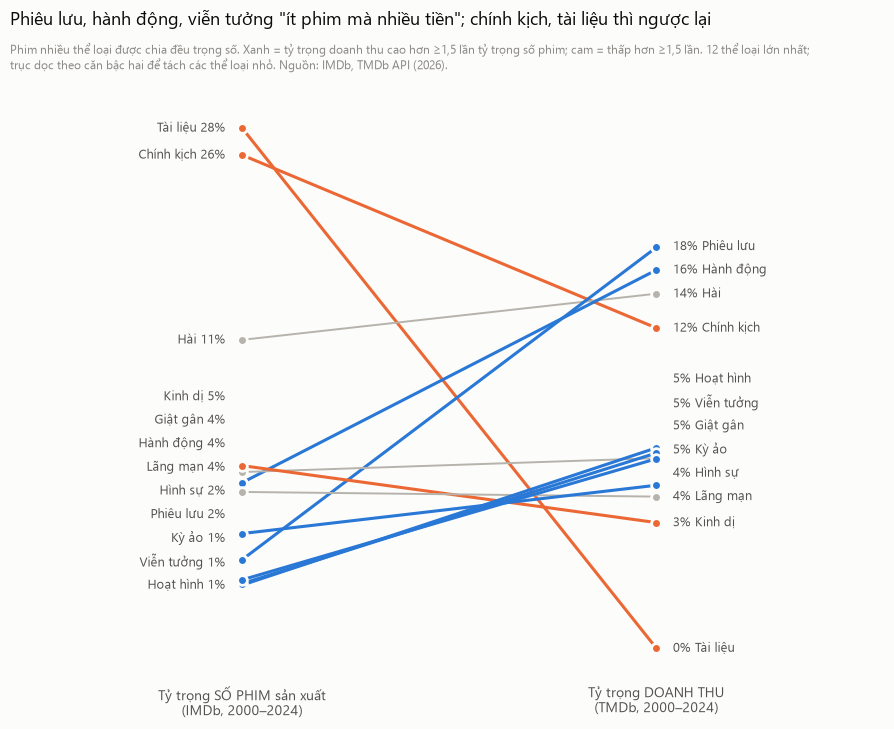

In [6]:
allm = duckdb.sql(f"""SELECT genres FROM read_parquet('{P("imdb_movies_all.parquet")}')
                      WHERE NOT is_adult AND start_year BETWEEN 2000 AND 2024 AND genres IS NOT NULL""").df()
gc = allm.assign(g=allm["genres"].str.split(",")).explode("g")
gc["w"] = 1 / gc.groupby(level=0)["g"].transform("size")
share_n = gc.groupby("g")["w"].sum() / gc["w"].sum()
f2 = fin[fin["release_date"].dt.year.between(2000, 2024)]
gr = f2.assign(g=f2["genres"].str.split(",")).explode("g")
gr["w"] = gr["revenue"] / gr.groupby(level=0)["g"].transform("size")
share_r = gr.groupby("g")["w"].sum() / gr["w"].sum()
G = (share_n + share_r).nlargest(12).index
fig, ax = plt.subplots(figsize=(9, 7.4))
V.style_axes(ax, grid=None)
ax.spines["bottom"].set_visible(False)
def spread(vals, gap):
    """Dàn nhãn theo trục dọc để khoảng cách giữa hai nhãn liền kề >= gap."""
    order = np.argsort(vals)
    out = np.array(vals, dtype=float)
    for k in range(1, len(order)):
        prev, cur = order[k - 1], order[k]
        out[cur] = max(out[cur], out[prev] + gap)
    return out


T = np.sqrt                                          # trục căn bậc hai: tách các thể loại nhỏ
la = spread([T(share_n.get(g, 0)) for g in G], 0.022)
lb = spread([T(share_r.get(g, 0)) for g in G], 0.022)
for k, g in enumerate(G):
    a, b = share_n.get(g, 0), share_r.get(g, 0)
    up = b > a * 1.5
    down = b < a / 1.5
    color = V.BLUE if up else (V.ORANGE if down else V.OTHER)
    ax.plot([0, 1], [T(a), T(b)], color=color, linewidth=2.2 if (up or down) else 1.4,
            marker="o", markersize=7, markeredgecolor=V.SURFACE, markeredgewidth=2)
    ax.text(-0.04, la[k], f"{V.GENRE_VI.get(g, g)} {a:.0%}", ha="right", va="center", color=V.INK2, fontsize=9)
    ax.text(1.04, lb[k], f"{b:.0%} {V.GENRE_VI.get(g, g)}", ha="left", va="center", color=V.INK2, fontsize=9)
ax.set_xlim(-0.55, 1.55)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Tỷ trọng SỐ PHIM sản xuất\n(IMDb, 2000–2024)", "Tỷ trọng DOANH THU\n(TMDb, 2000–2024)"], color=V.INK2)
ax.tick_params(axis="x", pad=8)
ax.set_yticks([])
V.titles(fig, "Phiêu lưu, hành động, viễn tưởng \"ít phim mà nhiều tiền\"; chính kịch, tài liệu thì ngược lại",
         f"Phim nhiều thể loại được chia đều trọng số. Xanh = tỷ trọng doanh thu cao hơn ≥1,5 lần tỷ trọng số phim; "
         f"cam = thấp hơn ≥1,5 lần. 12 thể loại lớn nhất; trục dọc theo căn bậc hai để tách các thể loại nhỏ. {SRC_FIN}")
V.save(fig, FOLDER, "04_genre_count_vs_revenue_slope")

**Nhận xét.** Hai bức tranh gần như đảo ngược: **tài liệu** chiếm 28% số phim sản xuất nhưng ~0% doanh thu; **chính kịch** 26% → 12%. Ngược lại **phiêu lưu** (2% → 18%), **hành động** (4% → 16%), **hoạt hình, viễn tưởng, kỳ ảo** (~1% → 5%) là các thể loại "ít phim mà nhiều tiền" — đúng là các thể loại của bom tấn Hollywood.

## 5. Nền tảng nào có kho phim "chất lượng" nhất? (IMDb × TMDb/JustWatch)

  wrote plots\5_combined\05_platform_catalog_quality.png


WindowsPath('D:/dulieulon/plots/5_combined/05_platform_catalog_quality.png')

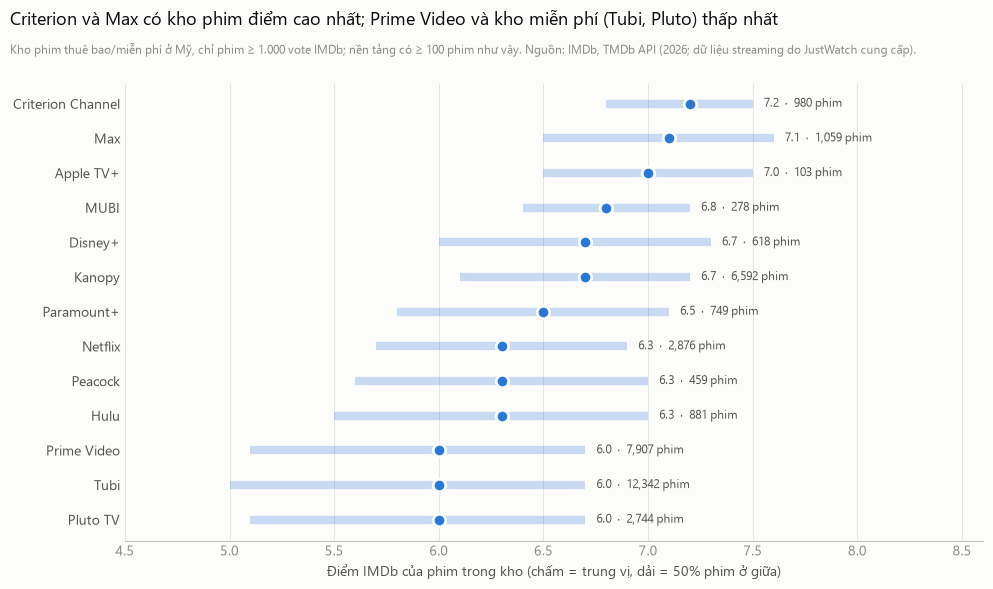

In [7]:
wp = duckdb.sql(f"SELECT imdb_id, country, kind, provider FROM read_parquet('{P('tmdb_watch_providers.parquet')}') WHERE country = 'US'").df()
BR = {"netflix": "Netflix", "prime video": "Prime Video", "amazon prime": "Prime Video", "disney": "Disney+",
      "hbo max": "Max", "hulu": "Hulu", "peacock": "Peacock", "paramount": "Paramount+", "apple tv": "Apple TV+",
      "mubi": "MUBI", "criterion": "Criterion Channel", "tubi": "Tubi", "pluto": "Pluto TV", "kanopy": "Kanopy"}


def brand(p):
    l = p.lower()
    if "channel" in l and "criterion" not in l:
        return None
    for k, v in BR.items():
        if k in l:
            return v
    return "Max" if l in ("max", "max with ads") else None


wp["brand"] = wp["provider"].map(brand)
cat = wp[wp["kind"].isin(["flatrate", "free", "ads"]) & wp["brand"].notna()].drop_duplicates(["imdb_id", "brand"])
cat = cat.merge(mv[["imdb_id", "avg_rating", "num_votes"]], on="imdb_id").query("num_votes >= 1000")
stats = cat.groupby("brand")["avg_rating"].agg(["median", "count", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
stats.columns = ["median", "n", "q1", "q3"]
stats = stats[stats["n"] >= 100].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 6))
V.style_axes(ax, grid="x")
y = np.arange(len(stats))
ax.hlines(y, stats["q1"], stats["q3"], color=V.BLUE, linewidth=6, alpha=0.25)
ax.plot(stats["median"], y, "o", markersize=9, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
for yi, (name, r) in zip(y, stats.iterrows()):
    ax.annotate(f"{r['median']:.1f}  ·  {int(r['n']):,} phim", xy=(r["q3"], yi), xytext=(8, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=8.5)
ax.set_yticks(y)
ax.set_yticklabels(stats.index, color=V.INK2)
ax.set_xlim(4.5, 8.6)
ax.set_xlabel("Điểm IMDb của phim trong kho (chấm = trung vị, dải = 50% phim ở giữa)")
V.titles(fig, "Criterion và Max có kho phim điểm cao nhất; Prime Video và kho miễn phí (Tubi, Pluto) thấp nhất",
         f"Kho phim thuê bao/miễn phí ở Mỹ, chỉ phim ≥ 1.000 vote IMDb; nền tảng có ≥ 100 phim như vậy. {SRC}")
V.save(fig, FOLDER, "05_platform_catalog_quality")

**Nhận xét.** **Criterion Channel (7,2)** và **Max (7,1)** có trung vị điểm IMDb cao nhất, rồi Apple TV+, MUBI. **Prime Video, Tubi, Pluto TV (6,0)** thấp nhất — đây là các kho **lớn** (hàng nghìn phim) nên chứa nhiều phim trung bình. Có một sự đánh đổi rõ: **kho càng lớn, điểm trung vị càng thấp**.

## 6. Phim nổi tiếng và phim hay có dễ xem hợp pháp hơn? (IMDb × TMDb/JustWatch)

  wrote plots\5_combined\06_availability_heatmap.png


WindowsPath('D:/dulieulon/plots/5_combined/06_availability_heatmap.png')

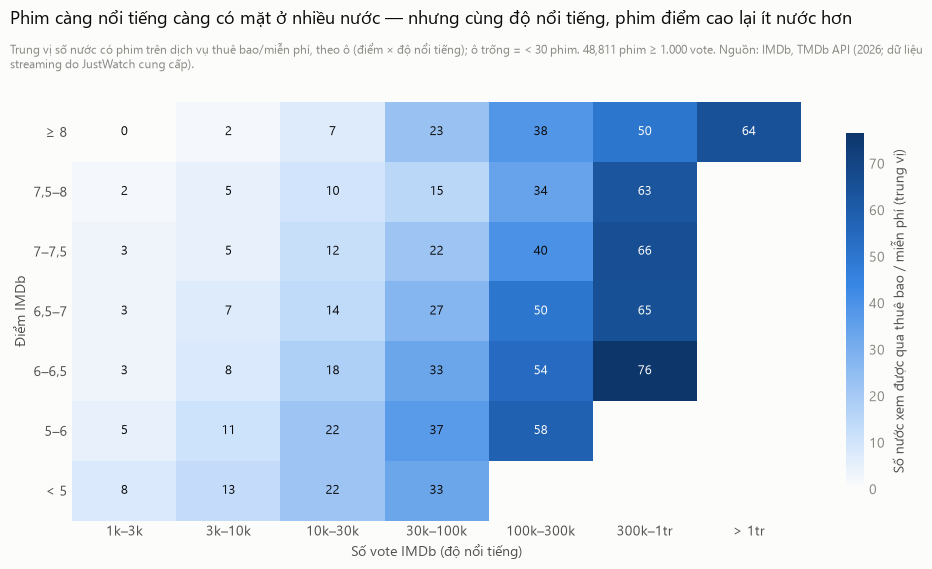

In [8]:
av = mv[(mv["num_votes"] >= 1000) & mv["avg_rating"].notna()].copy()
av["vote_bin"] = pd.cut(np.log10(av["num_votes"]), [3, 3.5, 4, 4.5, 5, 5.5, 6, 7],
                        labels=["1k–3k", "3k–10k", "10k–30k", "30k–100k", "100k–300k", "300k–1tr", "> 1tr"])
av["rating_bin"] = pd.cut(av["avg_rating"], [0, 5, 6, 6.5, 7, 7.5, 8, 10],
                          labels=["< 5", "5–6", "6–6,5", "6,5–7", "7–7,5", "7,5–8", "≥ 8"])
grid = av.pivot_table(index="rating_bin", columns="vote_bin", values="n_countries_streaming", aggfunc="median", observed=False)
cnt = av.pivot_table(index="rating_bin", columns="vote_bin", values="imdb_id", aggfunc="count", observed=False)
grid = grid.where(cnt >= 30)
fig, ax = plt.subplots(figsize=(10, 5.8))
im = ax.imshow(grid.values[::-1], cmap=V.SEQ, aspect="auto", vmin=0)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[::-1][i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color=V.SURFACE if v > np.nanmax(grid.values) * 0.55 else V.INK)
ax.set_xticks(range(grid.shape[1]))
ax.set_xticklabels(grid.columns, color=V.INK2)
ax.set_yticks(range(grid.shape[0]))
ax.set_yticklabels(grid.index[::-1], color=V.INK2)
ax.set_xlabel("Số vote IMDb (độ nổi tiếng)")
ax.set_ylabel("Điểm IMDb")
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.85)
cb.outline.set_visible(False)
cb.set_label("Số nước xem được qua thuê bao / miễn phí (trung vị)", color=V.INK2)
V.titles(fig, "Phim càng nổi tiếng càng có mặt ở nhiều nước — nhưng cùng độ nổi tiếng, phim điểm cao lại ít nước hơn",
         f"Trung vị số nước có phim trên dịch vụ thuê bao/miễn phí, theo ô (điểm × độ nổi tiếng); ô trống = < 30 phim. "
         f"{len(av):,} phim ≥ 1.000 vote. {SRC}")
V.save(fig, FOLDER, "06_availability_heatmap")

**Nhận xét.** **Độ nổi tiếng** là yếu tố chính: phim > 300 nghìn vote có mặt trên dịch vụ thuê bao/miễn phí ở 50–76 nước, phim < 3 nghìn vote chỉ ở 2–8 nước. Bất ngờ là **ở cùng độ nổi tiếng, phim điểm cao lại có mặt ở ÍT nước hơn** (nhóm 300k–1tr vote: 6–6,5 điểm → 76 nước, ≥ 8 điểm → 50 nước) — có thể vì phim kinh điển/nghệ thuật được cấp phép hẹp và đắt hơn, còn phim giải trí đại chúng được phân phối rộng.

## Tóm tắt phần 2

| Câu hỏi | Trả lời |
|---|---|
| Phim hay có ăn khách? | Chỉ một chút (ρ ≈ 0,20) |
| Nhiều tiền → phim hay? | Không; ngân sách chỉ giúp tránh phim quá tệ |
| Thể loại | Tài liệu/chính kịch: nhiều phim, ít tiền; phiêu lưu/hành động: ngược lại |
| Chất lượng kho phim | Criterion, Max cao nhất; kho lớn (Prime, Tubi) thấp nhất |
| Khả năng xem hợp pháp | Do độ nổi tiếng quyết định; phim điểm cao không dễ xem hơn |